<a href="https://colab.research.google.com/github/LcNardn/cb2330-portfolio/blob/main/cb2330_project/ProjectCB2330.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Statistical modeling for the CB 2330 Scientific Computing in Life Science course

## PROJECT CARD
+ **The paper**: The paper title is: "*Most ornamental plants on sale in garden centres are unattractive to flower-visiting insects*" by Mihail Garbuzov, Karin Alton and Francis L. W. Ratnieks, 2017

+ **The data object**:  determine the proportions of flowering ornamentals being sold that are attractive to flower-visiting insects.

+ **The random variable chosen**: The random variable we have chose to model is $\mathrm{X}$ that express the counts of insects visiting patches of plants in a garden center in 1 meter square ( $n_{insects}$ , which is dimensionless).

+ **What the paper does**: The researchers have surveyed six garden centres in Sussex, UK, within c. 30 km of each other. Each retail center was surveyed over two days in 2015, between 9 July and 19 September 2015, by making 12 counts of insects visiting patches of each ornamental plant on display for sale that was in bloom, between 10:00 and 16:30 BST at 30-minute intervals.

+ **The generative model proposed**: We propse a negative binomial model for $\mathrm{X}$.
$$
\mathrm{X} \sim \mathcal{NB}(c,p)
$$

+ **Parameters and assumptions**: the parameter are *c* and *p*, both dimensionless. The *c* parameter regulates the width of the model: if we increase *c*, the distribution would become wider and the mean would shift to the right.
   On the other hand *p* regulates where the peak of the dustribution is situated: if we increase *p*, the distribution would be moved to the left.

  The assumptions are:   
  -   the insect behave equally in all the garden centers.
  -   all the different species of insect can approximately be considered as one
  -   the plants flower and insects behave the same during the study period
  -   *c* and *p* are independent (see section 4.2.1 for the empirical correlation coefficents )

+ **The forward simulation**:
We simulate 10.000 random variables for each garden centers with the Monte Carlo method. First we generate our probabilities with rng, then we divide our data in bins, following:

$$
\sum_{k=0}^{x-1} P(\mathrm{X}=k \vert{} c, p) \le r < \sum_{k=0}^{x} P(\mathrm{X}=k \vert{} c, p)
$$

+ **The parameterization/fitting**:
We can try to find the best parameters' values by fitting the distribution to the data.

  To achieve this we first score each combination of values, through the `nll()` function, then we compare the score through the gradient descent method with an adaptive step size.

+ **What/if the model adds to the paper**: By fitting a distribution to each garden centre, we can compare the overall attractiveness of their unique plant compositions. Examining the shape and mean of these distributions allows us to deduce whether a centre's total insect presence is supported by a broad baseline of moderately attractive plants, or if it relies on a few highly attractive varieties.

  Moreover simulating the process we can acquire way more data than observing insects presence on the field.

+ **Model limitations/how it breaks**: The limits of our model are mainly due to the strong assumption we made at the start of the process and the original dataset we have.
  In fact the model can not handle when:
  *   we consider more one insects' behaviour,
  *   insect activity vary significantly in the period in analysis,
  *   singular plant blossing period does not extend over a month
  *   there are enviromental differences ( i.e. rain or insect colony direclty in the garden center)

  Further more our starting data comes from a singular 30 km radius area in the UK, which limits greatly the extend of which our model can be used outside of it.


## **1. Paper summary**
To reach the objective, the researchers have surveyed six garden centres in Sussex, UK, within c. 30 km of each other.

Each retail center was surveyed over two days in 2015, between 9 July and 19 September 2015, by making 12 counts of insects visiting patches of each ornamental plant on display for sale that was in bloom, between 10:00 and 16:30 BST at 30-minute intervals.

The garden centres were chosen to reflect the diversity of retail types, and included three independent businesses, each with a single site, and three that were branches belonging to medium or large chains.

The independents propagated and grew some or all of their stock, while the chains retailed stock brought in from wholesale suppliers.

The plant sruveyed were between 59 and 74 varieties covering between 14.7 and 37.6 m2 per garden centre It was take into account if the variety was present on the UK’s Royal Horticultural Society’s ‘Perfect for Pollinators’ list (RHS, 2014), or had any bee- or pollinator-friendly symbol or logo on the pot or label, including the RHS Perfect for Pollinators logo.

There was some overlap between the two categories.

### 1.1 The data
The data from the paper contains all the mean counts of insects per m$^2$ of each species of the garden centers observed

In [5]:
# the libraries that we will use in the notebook
import math
import matplotlib.pyplot as plt
import scipy.stats as st
import numpy as np

# each garden center has its list of mean counts [insects/m^2]
data = {}

# varieties surveyed: 68, RHS PfP rate: 46%
data["Garden Pride"] = [14.71, 7.78, 6.78, 4.38, 3.67, 2.67, 2.65, 2.65, 1.95, 1.77,
                        1.7, 1.67, 1.63, 1.18, 1.13, 1.04, 0.99, 0.98, 0.85, 0.85,
                        0.83, 0.74, 0.68, 0.68, 0.68, 0.54, 0.52, 0.48, 0.46, 0.42,
                        0.41, 0.41, 0.41, 0.41, 0.34, 0.27, 0.27, 0.27, 0.24, 0.21,
                        0.2, 0.19, 0.19, 0.17, 0.14, 0.14, 0.14, 0.14, 0.1, 0.1,
                        0.07, 0.07, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,
                        0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]

# varieties surveyed: 69, RHS PfP rate: 38%
data["Wyevale"] = [14.92, 14.15, 7.96, 7.54, 7.31, 6.05, 5.09, 4.41, 3.83, 3.82,
                   3.77, 3.54, 2.83, 2.36, 2.31, 2.21, 1.7, 1.68, 1.51, 1.27,
                   0.94, 0+.93, 0.9, 0.88, 0.69, 0.68, 0.66, 0.58, 0.53, 0.48,
                   0.48, 0.47, 0.46, 0.46, 0.42, 0.39, 0.34, 0.29, 0.28, 0.27,
                   0.22, 0.19, 0.17, 0.11, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,
                   0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,
                   0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]

# varieties surveyed: 59, RHS PfP rate: 68%
data["Staverton"] = [13.75, 11.25, 10.61, 10.53, 9.23, 9.09, 6.96, 6.79, 6.75, 6.62,
                     6.55, 6.38, 6.37, 6.29, 6.29, 5.94, 5.63, 5.13, 5.05, 4.27, 3.72,
                     2.72, 2.68, 2.53, 2.36, 2.26, 2.21, 1.99, 1.96, 1.8, 1.77, 1.75,
                     1.7, 1.65, 1.52, 1.52, 1.47, 1.33, 1.33, 1.32, 1.18, 1.16, 1.16,
                     1.01, 1.01, 0.88, 0.71, 0.66, 0.59, 0.59, 0.59, 0.52, 0.47, 0.44,
                     0.38, 0.29, 0.26, 0.24, 0.07, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,
                     0.0, 0.0, 0.0]

# varieties surveyed: 74, RHS PfP rate: 62%
data["Marchants"] = [47.08, 36.67, 32.92, 30.79, 28.97, 28.56, 25.46, 23.02, 21.96, 21.24,
                     20.48, 20.16, 20.0, 19.91, 18.52, 17.94, 17.8, 17.71, 17.71, 13.78,
                     13.05, 12.86, 12.41, 12.24, 11.11, 11.11, 10.82, 10.61, 9.26, 8.33,
                     7.94, 7.91, 7.83, 7.72, 7.23, 6.88, 6.35, 5.95, 5.73, 4.76, 4.63,
                     4.46, 3.66, 3.24, 2.31, 2.27, 2.22, 2.22, 1.96, 1.82, 1.77, 1.52,
                     1.46, 1.46, 1.41, 1.33, 1.26, 1.08, 1.06, 1.04, 1.01, 0.8, 0.79,
                     0.66, 0.58, 0.19, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]

# varieties surveyed: 59, RHS PfP rate: 59%
data["Hillier"] = [51.52, 36.9, 31.31, 27.54, 18.04, 17.94, 16.98, 16.67, 15.93, 11.11,
                   10.61, 10.53, 10.17, 8.49, 8.49, 7.74, 7.07, 6.6, 6.23, 5.66, 5.56,
                   5.21, 4.94, 4.42, 4.33, 3.89, 3.61, 3.47, 3.45, 3.4, 3.33, 3.17, 3.17,
                   2.96, 2.78, 2.65, 1.99, 1.85, 1.85, 1.17, 1.04, 0.98, 0.58, 0.51, 0.35,
                   0.3, 0.16, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]

# varieties surveyed: 66, RHS PfP rate: 59%
data["Wych Cross"] = [145.83, 77.81, 56.59, 46.91, 42.79, 40.42, 39.3, 35.11, 31.24,
                      30.56, 22.47, 20.83, 20.45, 20.3, 20.14, 19.89, 18.67, 18.57,
                      17.68, 17.46, 16.5, 15.16, 14.8, 14.4, 14.21, 13.86, 13.75,
                      13.74, 12.73, 12.41, 11.79, 11.79, 11.32, 8.49, 8.47, 8.25,
                      7.86, 7.47, 7.43, 7.37, 6.76, 6.32, 5.99, 5.21, 5.16, 4.55,
                      4.27, 4.13, 3.77, 3.68, 3.48, 3.03, 2.97, 2.95, 2.4, 2.38,
                      2.32, 1.95, 1.6, 1.55, 1.21, 0.97, 0.66, 0.65, 0.57, 0.0, 0.0]


## **2. Choice of the generative model**
As we are counting the number of insects, which is a discrete random variable, we need a discrete model.

Considering the process, the main choices are the Poisson distribution and the negative binomial distribution. Given that each flower in the garden center has a different level of attractiveness, the Poisson distribution is not ideal, as the rate parameter $\lambda$ tends to vary from plant to plant on our model and chooisng a Poisson could lead to oversimplifications.

Therefore, we have chosen the negative binomial distribution $P(\mathrm{X} = x | c,p)$.

When the parameter *c* is a natural number the distribution follows this formula:

$$
P(\mathrm{X}=x|c,p) = \binom{x+c-1}{x}p^c(1-p)^x
$$
When *c* is a real number the formula is:
$$
P(\mathrm{X}=x|c,p) = \frac{\Gamma(x+c)}{\Gamma(x)\Gamma (c)}p^c(1-p)^x \quad\text{where}\quad \Gamma(x) = \int_{0}^{+∞} t^{x-1}e^t dt
$$

Since the binomial operator is only defined for natural numbers.

The implementation of this formula would require us to integrate for the function $\Gamma$, which goes beyond the scope of this course, so to simplify the coding process we used the negative binomial distribution of the `scipy.stats` library.


### 2.1 Parameters
The model features two parameters: $c$ and $p$, a dimensionless success probability bounded between 0 and 1. An increase in $c$ raises the expected mean number of insects per $m^2$ and reduces dispersion, whereas an increase in $p$ decreases the expected mean insect count by lowering the likelihood of higher densities.
Since the true parameters are unknown, we can estimate them by using the values of empirical mean and variance and using them in the theoretical population formulas.

$$
\begin{cases}
\widehat\mu= \frac{c(1-p)}{p} \\
\widehat\sigma^2= \frac{c(1-p)}{p^2}
\end{cases}
$$

In the end we have found that the values for *c* and *p* are:

$$
c=\frac{\widehat{\mu}^{2}}{ \widehat{\sigma}^2 - \widehat{\mu}} \quad \text{and} \quad
p=\frac{\widehat{\mu}}{\widehat{\sigma}^2}
$$

In [6]:
# calculating empirical means, empirical variances and parameters for different garden centers
def emp_mean(sample):
  return sum(sample) / len(sample)

def emp_variance(sample):
  temp = emp_mean(sample)
  return sum( (s - temp) ** 2 for s in sample ) / (len(sample) - 1)

means = {}
variances = {}
params = {}
for key,values in data.items(): # for all garden centers
  # mean
  mean = emp_mean(values)
  means[key] = mean

  # variance
  variance = emp_variance(values)
  variances[key] = variance

  # parameters following the formulas above
  c = mean ** 2 / (variance - mean)
  p = mean / variance
  params[key] = (c,p)

# showing the values of mean and variance
print(f"{'Garden center':<15} {'Mean [N_insects]':<20} {'Standard deviation [N_insects]'}\n")
for garden in data.keys():
    print(f"{garden:<15} {means[garden]:<20.4f} {(variances[garden] ** 0.5):.4f}")


Garden center   Mean [N_insects]     Standard deviation [N_insects]

Garden Pride    1.0428               2.2004
Wyevale         1.5726               2.9537
Staverton       2.9171               3.2971
Marchants       9.4265               10.3837
Hillier         6.6108               9.8055
Wych Cross      15.7216              21.8066


### 2.2 Assumptions

The assumptions are:   

*   The environmental conditions and insect behavior are assumed to be equal across the different garden center given that they are close to one another.
*   Different insect species are pooled together and treated as a single aggregate count variable.
*   Plant flowering intensity and insect activity remain relatively stable throughout the study period, despite data being collected across different periods of summer.
*    *c* and *p* are independent (see section 4.2.1 for the empirical correlation coefficents )

## **3. The forward simulation**

To simulate the random variable we can use the Monte Carlo method, first we need to generate real random numbers in the interval [0,1) with a uniform distribution, which will serve as our probabilities.

Then we divide our data in 15 bins, the first 14 of widht 5 $n_{insects}$ in 1 $m^{2}$ and the last that contains any $n_{insects}$ in 1 $m^{2}$ over the count of 60.

Each random number (*r*) is assigned a bin, based on:
$$
\sum_{k=0}^{x-1} P(\mathrm{X}=k \vert{} c, p) \le r < \sum_{k=0}^{x} P(\mathrm{X}=k \vert{} c, p)
$$

We then run 10.000 simulations for each garden centers and we show the resulting plots.


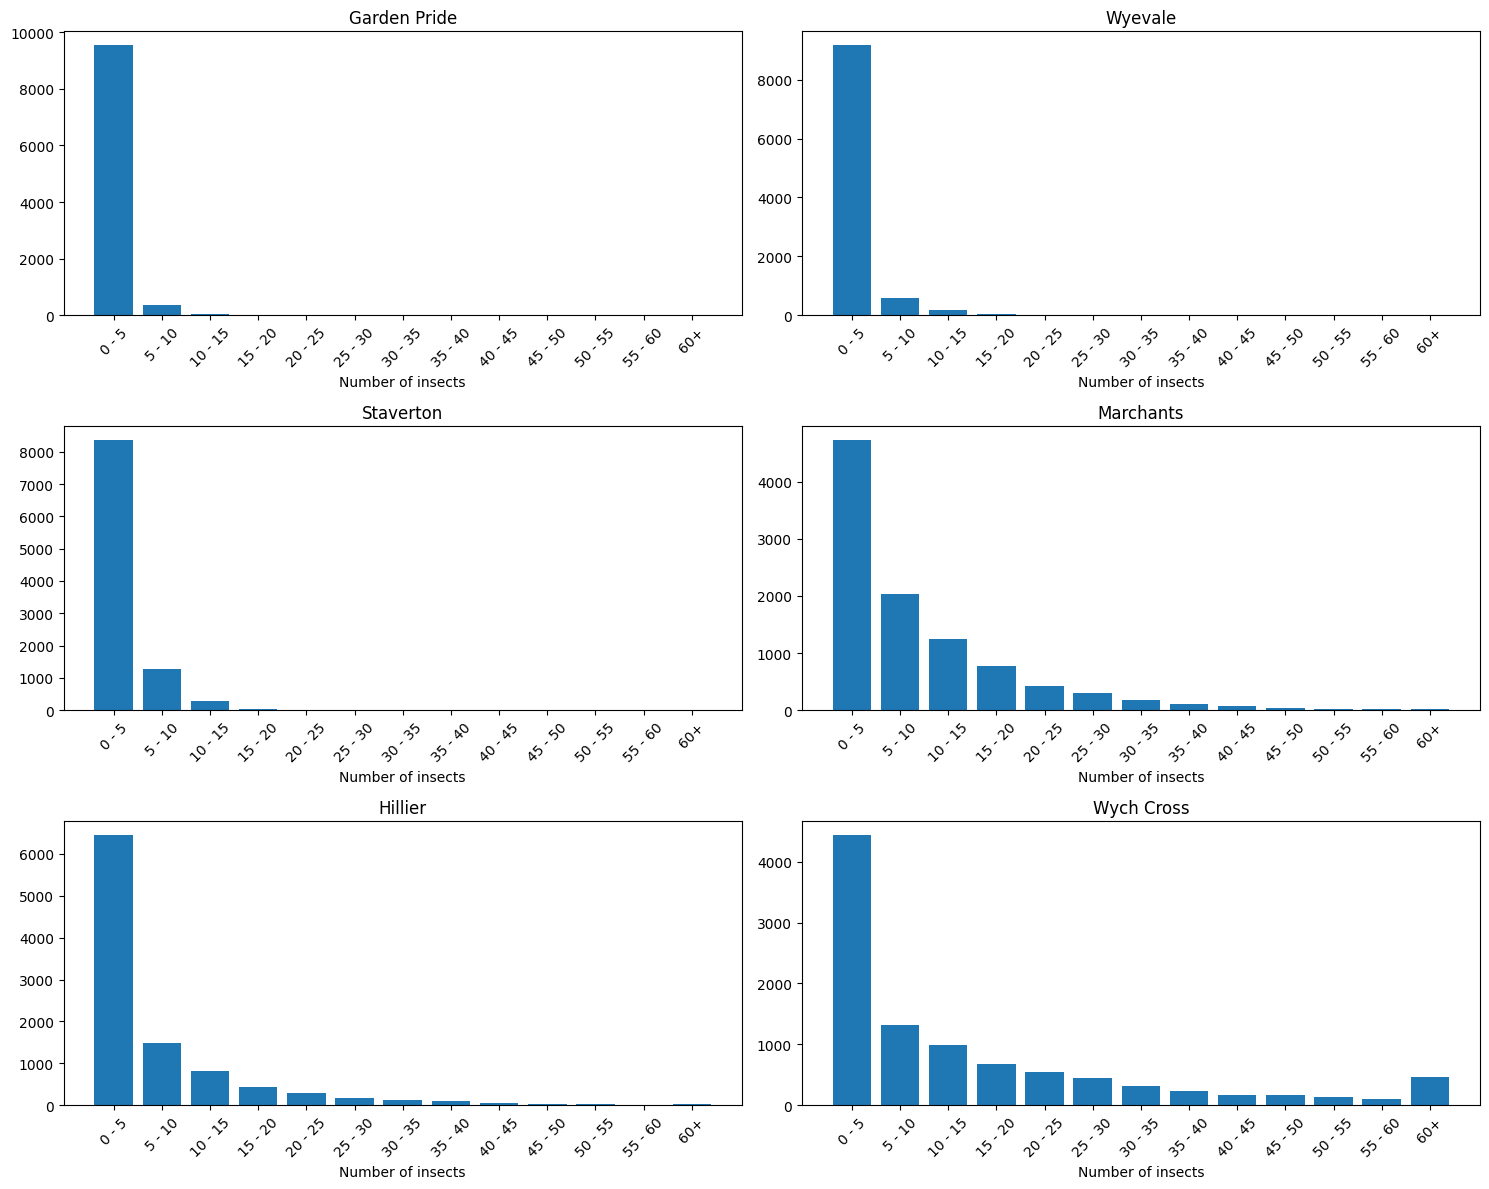

In [7]:
# Numbers for the generation of random numbers
A_LCG = 1664525
C_LCG = 1013904223
M_LCG = 2 ** 32
SEED = 1

# Definition of the bins
BIN_WIDTH = 5
N_BINS = 13

# the number of elements in one simulated sample
N = 10000

# first we need the functions for the rng
def lcg(state, a, c, m):
    """The next state of a linear congruential generator: s_{i+1} = (a * s_i + c) mod m."""
    return (a * state + c) % m


def uniforms(k, seed):
    """A list of k numbers on [0, 1): the generator run k times from the seed, each state divided by m."""
    out = [0.0] * k
    state = seed
    for i in range(k):
        state = lcg(state, A_LCG, C_LCG, M_LCG)
        out[i] = state / M_LCG
    return out

# We apply the Monte Carlo method and we obtain the number of insects corresponding to the probability r (generated by rng) in the distribution.
def simulation_nbinom(n, c, p):
  """Returns a simulated sample of length n from a negative binomial distribution with parameters c and p"""
  bins = [0] * N_BINS

  # We generate one random number for each point in our sample
  n_insects_ex=uniforms(n, SEED)

  for i in range(n):
    prob = 0
    for edge in range(BIN_WIDTH, BIN_WIDTH*N_BINS, BIN_WIDTH): # for each edge that separates two bins

      if prob <= n_insects_ex[i] < st.nbinom.cdf(edge, c, p): # if our generated probability falls in the interval, we add one element to the bin
        bins[int(edge/BIN_WIDTH)-1] += 1

      prob = st.nbinom.cdf(edge, c, p)

  bins[len(bins)-1] += len(n_insects_ex) - sum(bins) # all the bins that exeed the scale are summed in the last bin

  return bins

simulations = {}
gardens = list(data.keys())
n_gardens = len(gardens)
cols = 2
rows = 3

fig, axes = plt.subplots(rows, cols, figsize=(15, 4 * rows))
axes = axes.flatten()

for i, garden in enumerate(gardens):
    simulations[garden] = simulation_nbinom(N, *params[garden])

    x_labels = [f"{j*BIN_WIDTH} - {(j+1)*BIN_WIDTH}" for j in range(N_BINS-1)] + [f"{BIN_WIDTH*(N_BINS - 1)}+"]

    axes[i].bar(x_labels, simulations[garden])
    axes[i].set_title(garden)
    axes[i].set_xlabel("Number of insects")
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

Wych Cross garden center has a second peak in the last bin because it contains all the values that exceeds the scale. Given that this distribution has  a long tail towards the right, we can assume that the tail is longer than 70 or even 80 insects in 1 m².

Including infinitely many bins will result in the removal of the peak from the graph.





## **4. The parameterization/fitting**
Instead of calculating *c* and *p* directly from the data using the formula in section **2**, we can try to find the best parameters' values by fitting the distribution to the data.

To achieve this we first need a function to score each combination of values. We used the `nll()` function, which finds the value of the negative log-likelihood for a specific pair of parameters.

$$
\mathrm{NLL}(c,p) = - \sum_{x \in dataset} ln[P(\mathrm{X} = x | c,p)]
$$

Secondly we used the gradient descent method with an adaptive step to compare the scores and save the best value, through the function `descent_adaptive()`.

Subsequentely we used the result to built a plot for each garden center.

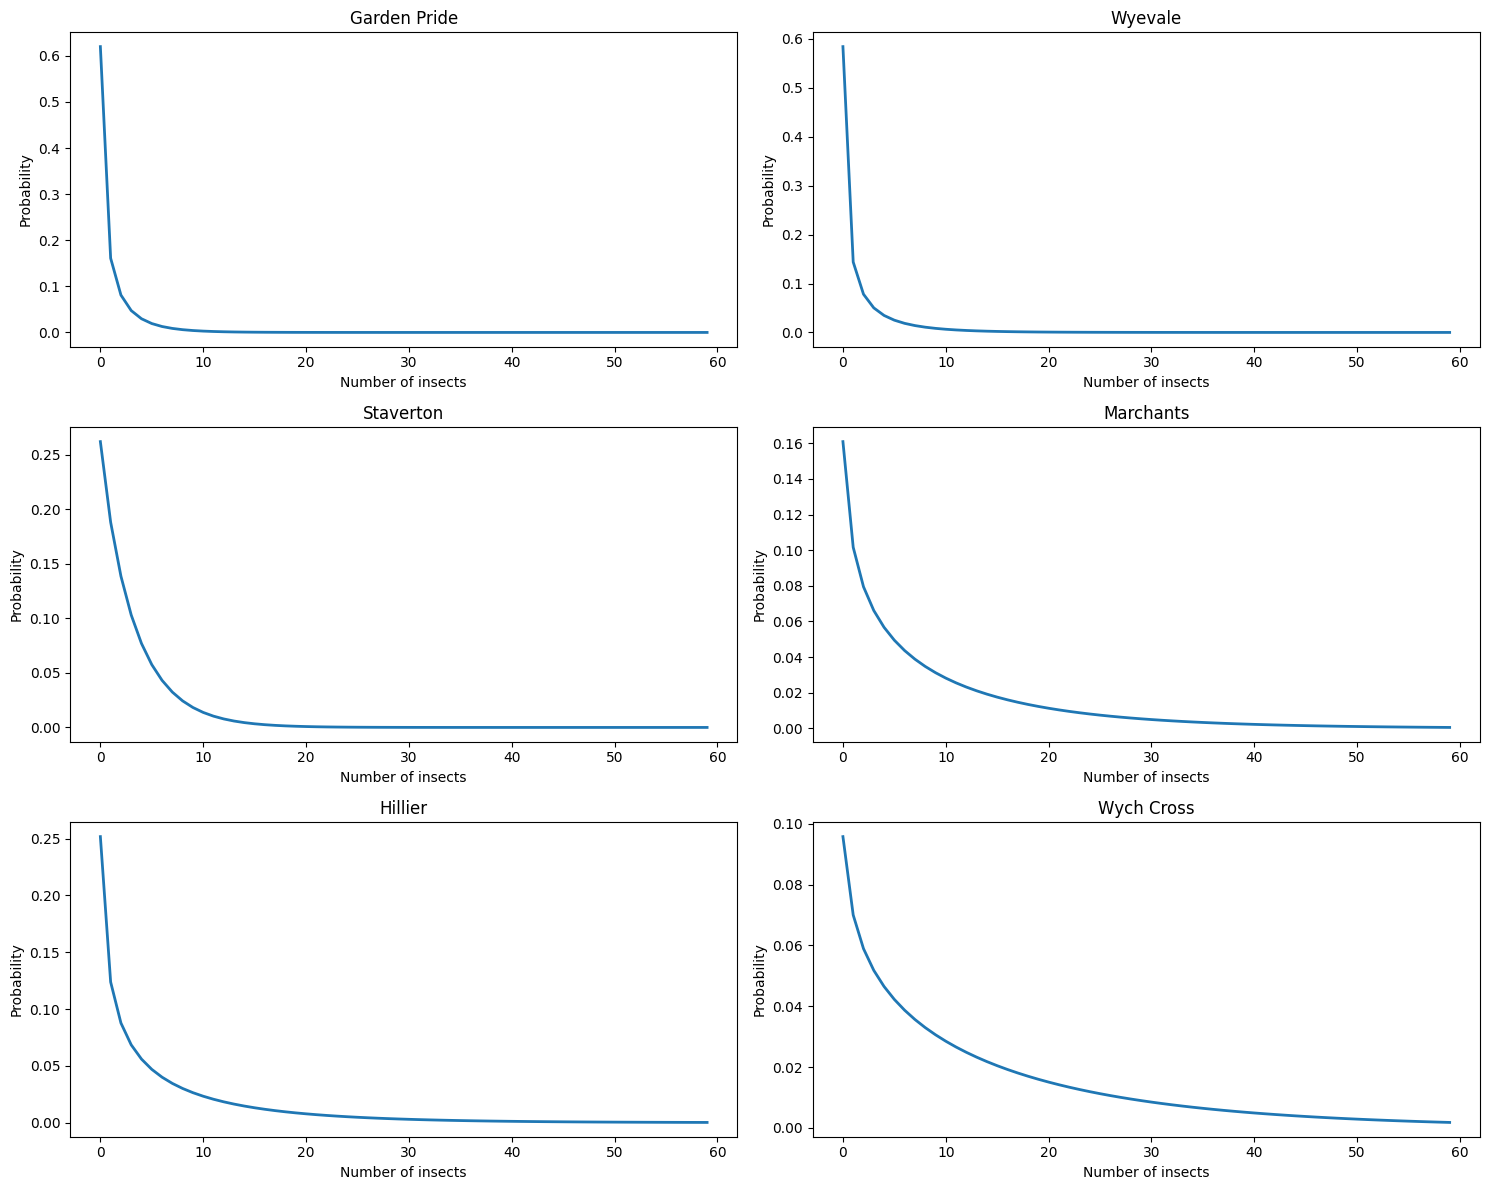

In [8]:
def nll(garden, c, p):
    """The negative of the sum of all the log-likelihoods"""
    score = 0
    for plant in data[garden]:
        # Convert float averages to discrete integers for the distribution
        count = int(round(plant))
        score -= math.log(st.nbinom.pmf(count, c, p) + 1e-10) # pseduocount to counter a probability of 0 and a NaN
    return score

def slope_at(garden, score_func, c, p, h):
    """Calculate an approximation of the gradient at the current point"""
    # the values must be in bounds
    c_plus = c + h
    c_minus = max(1e-10, c - h)
    p_plus = min(1 - 1e-10, p + h)
    p_minus = max(1e-10, p - h)

    # near boundaries the slope width could be less than 2h
    slope_c = (score_func(garden, c_plus, p) - score_func(garden, c_minus, p)) / (c_plus - c_minus)
    slope_p = (score_func(garden, c, p_plus) - score_func(garden, c, p_minus)) / (p_plus - p_minus)
    return slope_c, slope_p

def descend_adaptive(garden, score_func, c, p, alpha, h=0.01, tol=0.05, max_steps=40):
    """The walk of descend"""
    for step in range(max_steps): # to avoid an infinite progression

        slope_c, slope_p = slope_at(garden, score_func, c, p, h) # calculate the gradient

        # check if we are at a minimun. If so we can stop the cycle
        if abs(slope_c) < tol and abs(slope_p) < tol:
            break

        # calculate new candidates
        c_new = c - alpha * slope_c
        p_new = p - alpha * slope_p
        # Enforce bounds of the distribution c > 0 and 0 < p < 1
        c_new = max(1e-10, c_new)
        p_new = max(1e-10, min(1 - 1e-10, p_new))

        # update the hyperparameters and the parameters based on an improve
        if score_func(garden, c_new, p_new) < score_func(garden, c, p): # we are on the right track, increase the speed
            c, p = c_new, p_new
            alpha *= 1.2
        else:
            alpha /= 2 # We overshot, repeat the step with a lower magnitude

    return c, p # return the fitted parameters

params_fitting = {}
gardens = list(data.keys())
n_gardens = len(gardens)
cols = 2
rows = 3

fig, axes = plt.subplots(rows, cols, figsize=(15, 4 * rows))
axes = axes.flatten()

for i, garden in enumerate(gardens):
    # Fit the distribution
    c, p = descend_adaptive(garden, nll, 0.5, 0.5, 0.1, max_steps=1000)
    params_fitting[garden] = [c, p]

    # Calculate probabilities cleanly using NumPy arrays
    n_insects = np.arange(0, 60)
    prob = st.nbinom.pmf(n_insects, c, p)

    # Plot on the specific subplot axis
    axes[i].plot(n_insects, prob, linewidth=2)
    axes[i].set_title(garden)
    axes[i].set_xlabel("Number of insects")
    axes[i].set_ylabel("Probability")

plt.tight_layout()
plt.show()


### 4.1 Uncertainty
There 4 different ways to access uncertainty:
*  curvature
*  Profile likelihood
*  Bootstrapping
*  Bayesian posterior

We can exclude Bayesian posterior, as we have no access historical priors.

We are confident in our model and our distribution is heavy-tailed, therefore we can also exclude boostrapping.

Both profile likelihood and curvature can be used in our case. Therefore we implement both, even though the profile likelihood is not the best choice as it is computationally intensive.



#### 4.2.1 Covariance
Before describing the uncertainty we need to understand if we can evaluate the two parameter separetely (they are independent) or not.

To do so we need to calculate the covariance between c and p and we are going to calculate the empirical pearson coefficient.

The formula is the following:
$$
\rho_{cp}=\frac{\sigma_{cp}}{\sigma_c \sigma_p}
$$

and $\sigma_{cp}$ is calculate through:
$$
\sigma_{cp}=\mathbb{E}(cp)-\mathbb{E}(c)\mathbb{E}(p)
$$

However c and p could be non linear but still be correlated. Therefore we also calculate the empircial spearman correlation coefficent with the following formula:
The formula is the following:
$$
\rho_{R_c R_p}=\frac{\sigma_{R_c R_p}}{\sigma_{R_{c}} \sigma_{R_{p}}}
$$

and $\sigma_{R_c R_p}$ is calculate through:
$$
\sigma_{R_c R_p}=\mathbb{E}(R_c R_p)-\mathbb{E}(R_c)\mathbb{E}(R_p)
$$


In [9]:
# the way the two coefficient are calculated is the same, so we can do a function
def coefficient(c,p):
  mean_c=emp_mean(c)
  mean_p=emp_mean(p)

  std_c =(emp_variance(c))**0.5
  std_p = (emp_variance(p))**0.5


  sum_cp=0
  count=0
  for c_i,p_i in zip(c,p):
    sum_cp+=c_i*p_i
    count+=1

  covariance = sum_cp/count - mean_c * mean_p

  return covariance, covariance / ( std_c * std_p )

# pearson coefficient
c_s=[ params_fitting[g][0] for g in data.keys() ]
p_s=[ params_fitting[g][1] for g in data.keys() ]

covariance, pearson = coefficient(c_s,p_s)

print(f"The covariance between c and p is {covariance}. The pearson coefficent is {pearson}")

# using ranks and spearman coefficient in order to find out if they are non-linearly covariates
c_copy=c_s.copy()
p_copy=p_s.copy()
c_order=[]
p_order=[]
r_c=[]
r_p=[]

for i in range(len(c_s)):
  min_val=math.inf
  for c in c_copy:
      if c<min_val:
        min_val=c
  c_order.append(min_val)
  c_copy.remove(min_val)

for c in c_s:
  i=c_order.index(c)
  r_c.append(i)

for i in range(len(p_s)):
  min_val=math.inf
  for p in p_copy:
      if p<min_val:
        min_val=p
  p_order.append(min_val)
  p_copy.remove(min_val)


for p in p_s:
  i=p_order.index(p)
  r_p.append(i)

# spearman coefficient
covariance_r, rank = coefficient(r_c,r_p)

print(f"The rank covariance is: {covariance_r} and the spearman coefficent :{rank}")


The covariance between c and p is -0.002445820571964963. The pearson coefficent is -0.10554036525151421
The rank covariance is: -0.916666666666667 and the spearman coefficent :-0.261904761904762


According to the results both coefficent are very low.
Therefore we can assume c and p to be independent.

#### 4.2.2 Curvature
The curvature method describe the width of the curvature of the score function we use to score each pair of *c* and *p* to inform us about the certainty of the parameters.

In fact, the more this curvature is large, the less we are certain and viceversa.

To estimate this width we can use the second derivative, holding first one parameter and then the other.
$$
\frac{\partial^2 NLL}{\partial^2 c} \approx \frac{NLL(\hat{c}+h, \hat{p}) - 2NLL(\hat{c}, \hat{p}) + NLL(\hat{c}-h, \hat{p})}{h^2}
$$
$$
\frac{\partial^2 NLL}{\partial^2 p} \approx \frac{NLL(\hat{c}, \hat{p}+h) - 2NLL(\hat{c}, \hat{p}) + NLL(\hat{c}, \hat{p}-h)}{h^2}
$$

Then we calculate the error standard deviation of c an p as:
$$
\sigma_c= \frac{1}{\sqrt{\frac{\partial^2 NLL}{\partial^2 c}}}
\quad
\sigma_p= \frac{1}{\sqrt{\frac{\partial^2 NLL}{\partial^2 p}}}
$$


As it is inversly proportional the curvature

In the cell below we implement this method with separate calculation for *c* and *p* and report the values $c \pm \sigma_c$ and $p \pm \sigma_p$ for each garden center.

In [10]:
print(f"{'Garden center':<15} {'Sigma [c]':<30} {'Sigma [p]'}\n")

#curvature
h = 0.01
for garden in data.keys():

  # calculating a sigma only for c
  curvature_c= (nll(garden, params_fitting[garden][0]+h,params_fitting[garden][1] )-
               2*nll(garden, params_fitting[garden][0],params_fitting[garden][1] )+
               nll(garden, params_fitting[garden][0]-h,params_fitting[garden][1]))/h**2
  sigma_curv_c = 1/((curvature_c)**0.5)

  # calculating a sigma only for p
  curvature_p= (nll(garden, params_fitting[garden][0],params_fitting[garden][1]+h )-
               2*nll(garden, params_fitting[garden][0],params_fitting[garden][1] )+
               nll(garden, params_fitting[garden][0],params_fitting[garden][1]-h))/h**2
  sigma_curv_p = 1/((curvature_p)**0.5)

  print(f"{garden:<15} {params_fitting[garden][0]:.4f} +- {sigma_curv_c:<20.4f} {params_fitting[garden][1]:.4f} +- {sigma_curv_p:.4f}")

Garden center   Sigma [c]                      Sigma [p]

Garden Pride    0.3473 +- 0.0655               0.2525 +- 0.0446
Wyevale         0.2930 +- 0.0532               0.1598 +- 0.0323
Staverton       0.9500 +- 0.1171               0.2441 +- 0.0262
Marchants       0.6770 +- 0.0754               0.0673 +- 0.0091
Hillier         0.5314 +- 0.0738               0.0746 +- 0.0127
Wych Cross      0.7668 +- 0.0823               0.0469 +- 0.0063


#### 4.2.3 Profile Likelihood
The profile likelihood search for alternative strong candidates to *c* and *p* in an interval between the lowest `nll()` we have found and a benchmark, in this case: `lowest nll()+0.5` (our benchmark).
$$
\{c: NLL(c,p) \leq NLL(\hat{c} , \hat p)+ \frac{1}{2}\}
$$
$$
\{p: NLL(c,p) \leq NLL(\hat{c} , \hat p)+ \frac{1}{2}\}
$$
The width of this interval inform us on how certain the paramters are.

In cell below this method is implement through multiple for cycle and selection that saves the edges of the interval for both *c* and *p* and then print them.


In [11]:
print(f"{'Garden center':<15} {'Interval c':<20} {'Interval p'}\n")

# profile likelihood
for garden in data.keys():

  params_nll = nll(garden, params_fitting[garden][0], params_fitting[garden][1]) # our central score

  # initializing extremes
  low_c = params_fitting[garden][0]
  high_c=params_fitting[garden][0]
  low_p= params_fitting[garden][1]
  high_p=params_fitting[garden][1]

  for c in np.arange(0,2, 0.01):
    for p in np.arange(0,1, 0.01):
      if nll(garden, c, p) <= (params_nll + 0.5):
        if c < low_c:
          low_c=c
        if c > high_c:
          high_c=c
        if p < low_p:
          low_p=p
        if p > high_p:
          high_p=p

  print(f"{garden:<15} {low_c:.4f} - {high_c:<12.4f} {low_p:.4f} - {high_p:.4f}")




Garden center   Interval c           Interval p

Garden Pride    0.2600 - 0.4700       0.1900 - 0.3200
Wyevale         0.2300 - 0.3800       0.1200 - 0.2100
Staverton       0.7500 - 1.2200       0.2000 - 0.3000
Marchants       0.5900 - 0.8300       0.0600 - 0.0800
Hillier         0.4200 - 0.6300       0.0600 - 0.0900
Wych Cross      0.7500 - 1.1100       0.0469 - 0.0700


## **5. Conclusions**
Rather than relying solely on median insect counts like the paper does, examining the shape of these fitted distributions (specifically the thickness of the right tail) reveals a stark contrast in the retail environments and their baseline attractiveness to flower-visiting insects.

### 5.1 Pollinators friendly plants help the distribution

For Wyevale and Garden Pride, the fitted distributions start with a massive peak at zero. There is an approximate 60% probability that a random 1 m$^2$ plant patch at these centers will have zero insects on it. The curves drop off steeply, flattening out to near-zero probability before even reaching 10 insects per square meter. This mathematical shape also mirrors the raw inventory data, as Wyevale and Garden Pride stocked the lowest proportions of RHS "Perfect for Pollinators" (PfP) plants at 38% and 46%, respectively.

These models demonstrates that having an inventory dominated by unattractive plants suffocates the RHS PfP plants that are present.

In contrast, Staverton, Hillier, and Marchants exhibit healthier ecological profiles. For these garden centres, the probability of finding zero insects on a random patch drops, ranging from roughly 16% to 26%. Furthermore, their distribution tails are thicker. This correlates directly with their higher RHS PfP stocking rates of 59% to 68%.

### 5.2 Quality is better than quantity

Wych Cross emerges as the outlier in overall attractiveness. Its distribution yields a y-intercept below 0.10, meaning there is less than a 10% chance of encountering a completely barren plant in their displays. Its right tail is thick and long, maintaining a tangible probability of insect visits all the way up to the 60 insects per square meter mark. Despite having a PfP rate of 59% which similar to Hillier and Staverton, the shape of the Wych Cross distribution suggests a highly successful overall plant composition. It not only establishes a high baseline of visitation but features highly attractive "VIP (Very Important Plant)" plants that draw massive crowds, effectively pulling the entire ecosystem's average upward, which could also be seen in the initial data, as Campanula poscharskyana 'Blue Waterfall' reaches 145.83 insects per m$^2$.

In the end, these findings demonstrate that cultivating a thriving insect ecosystem requires more than simply choosing plants with 'pollinator-friendly' labels. The overall number of visiting insects depends heavily on the specific varieties of plants selected and choosing non-friendly plants will just dilute the echosystem's overall average.

## **6. Model limitations/how it breaks**
Our model presents some limits, in fact, we made some strong assumption at the start of the process: the conjecture that all the insect behave equally defy the laws of nature.

Therefore, the model breaks when we consider more one insects' behaviour.

We can reason similarly for the other two assumptions: insect activity can vary significantly in the span of three months also based on species and singular plant blossing period usually does not extend over a month.

Moreover our starting data comes from a singular 30 km radius area in the UK, which limits greatly the extend of which our model can be used outside of it.

Furthermore the enviroment can influence the process way more than the model can handle, as rain or insect colony direclty in the garden center can affect the insects counts greatly.